# Running EVE from command lines
EVE can be fully ran from command lines. Here are examples that fully provide an example. This notebook will perform loading, finding, fitting, post-processing, and displaying of EveSMLM-recorded DNA-PAINT nanoruler

Generally, finding/fitting routines exact methodology are stored in the RunInfo.txt after a GUI run, and thus can be extracted from there.

### Importing of code
All routines are loaded from EVE, along with some third-party packages

In [4]:
#Import all required scripts that are used by Eve
from CandidateFitting import *
from CandidateFinding import *
from Visualisation import *
from PostProcessing import *
from CandidatePreview import *
from Utils import *
from Utils import utils, utilsHelper
from EventDistributions import eventDistributions

#Importing 3rd-party packages
import appdirs
import os
import json

#Determining eve_data location
app_data_dir = appdirs.user_data_dir()
eve_data_folder = os.path.join(app_data_dir, 'UniBonn', 'Eve')

### Loading of EBS data
We recommend storing EBS event data in the HDF5 format, possible to convert in the Prophesee software. HDF5 event data can be loaded as follows:

In [5]:
#Loading the events from HDF between two timepoints
fileLoc = '/Users/trisso/EVE-software/eve_test/input/Nanoruler_Small.hdf5' #The location of a hdf5 file
events = utils.timeSliceFromHDF(fileLoc,requested_start_time_ms = 0,requested_end_time_ms=30*60e3)[0] #Loading the first 30 minutes of data

print(f"Event loading complete! Loaded {len(events)} events")

End of file reached while chunking HDF5
Event loading complete! Loaded 3435056 events


### Loading of global settings
EVE global settings are required, and can be loaded from the last GUI run like this, and/or set as shown.

In [6]:
#Load the global settings that were last used
with open(os.path.join('/Users/trisso/EVE-software/eve_test/input/settings.json'), 'r') as file:
    globalSettings = json.load(file)

#Global settings can be displayed and/or changed
globalSettings['MaxFindingBoundingBoxXY']['value'] = 20
print(json.dumps(globalSettings, indent=4))

{
    "MinFindingBoundingBoxXY": {
        "value": 3,
        "displayName": "Minimum size of a bounding box in px units"
    },
    "MinFindingBoundingBoxT": {
        "value": 10,
        "displayName": "Minimum size of a bounding box in ms units"
    },
    "MaxFindingBoundingBoxXY": {
        "value": 20,
        "displayName": "Maximum size of a bounding box in px units"
    },
    "MaxFindingBoundingBoxT": {
        "value": 1000,
        "displayName": "Maximum size of a bounding box in ms units"
    },
    "PixelSize_nm": {
        "value": 80,
        "displayName": "Pixel size (nm)"
    },
    "MetaVisionPath": {
        "value": "Enter Path to Metavision SDK!",
        "displayName": "MetaVision SDK Path"
    },
    "StoreConvertedRawData": {
        "value": true,
        "displayName": "Store converted raw data"
    },
    "StoreFileMetadata": {
        "value": true,
        "displayName": "Store metadata after running"
    },
    "StoreFinalOutput": {
        "value": t

### Finding routine
We look at all available functions currently present in the CandidateFinding folders, and perform an EigenFeature routine on the events

In [7]:
#Obtain all available routines in CandidateFinding
AllAvailableFunction = utils.functionNamesFromDir("CandidateFinding")
AllAvailableFunctionUserData = utils.functionNamesFromDir(eve_data_folder+"/CandidateFinding")

#Give terminal information about the finding routines
print("All available Finding Routines:")
for index, function in enumerate(AllAvailableFunction):
    print(f"{index+1}: {function}")

if len(AllAvailableFunctionUserData) > 0:
    print(f"\nAdditional available Finding Routines from UserData folder ({eve_data_folder+'/CandidateFinding'}):")
    for index, function in enumerate(AllAvailableFunctionUserData):
        print(f"{index+1}: {function}")

All available Finding Routines:
1: LoadExistingFinding.LoadExistingFinding
2: FrameBasedFinding.FrameBased_finding
3: EigenFeatureAnalysis.eigenFeature_analysis
4: EigenFeatureAnalysis.eigenFeature_analysis_and_bbox_finding
5: DBSCAN.DBSCAN_onlyHighDensity
6: DBSCAN.DBSCAN_allEvents
7: DBSCAN.DBSCAN_allEvents_remove_outliers


In [8]:
#We can also request information about required and optional parameters from one of these functions:
print(utils.printInformationFromFunction('EigenFeatureAnalysis.eigenFeature_analysis'))

Eigen-feature analysis
Help info 
Eigen-feature analysis. Performs spectral clustering methodology on the data to separate SMLM signal from noise. Practically finds clusters based on the Eigenvalues of the covariance matrix obtained by looking at the [Number of neighbours] closest points. Only events with an Eigenvalue lower than [Maximum Eigenvalue cutoff] are used. Also selects against linearity via [Linearity cutoff]
Required parameters
Number of neighbours [search_n_neighbours]: 
	Number of (closest) neighbouring events for the covariance determination 
	Default value: 50
Maximum Eigenvalue cutoff [max_eigenval_cutoff]: 
	Cutoff of maximum eigenvalue of events. Set to zero to auto-determine this-  and use Debug to visualise! 
	Default value: 0.0
Linearity cutoff [linearity_cutoff]: 
	Linearity (0-1) cutoff 
	Default value: 0.7
Ratio ms to px [ratio_ms_to_px]: 
	Ratio of milliseconds to pixels. 
	Default value: 20.0
DBSCAN epsilon [DBSCAN_eps]: 
	Eps of DBSCAN. 
	Default value: 4
DB

### Running a finding method
Based on the information above, we can run an EigenFeature finding on this dataset. Please observe that all keyword-arguments are strings in the command-line.

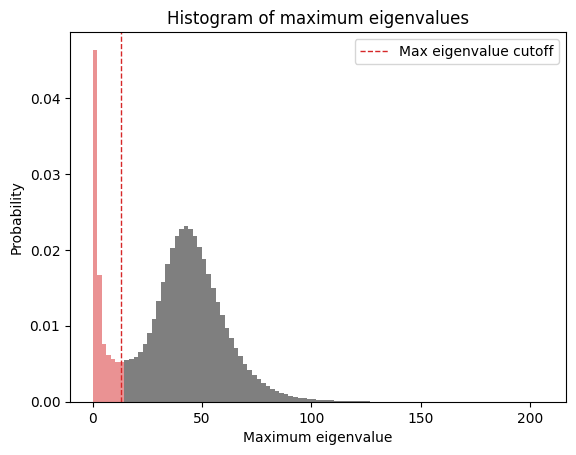

Finding complete! 7048 candidates are found. 
 
Provided metadata:
Eigen-Feature Finding ran for 12.295402526855469 seconds.


In [9]:
#Performing EigenFeature finding
#Note that by setting debug to true, we gain some insight about the EigenFeature method as well.
FindingResults = EigenFeatureAnalysis.eigenFeature_analysis(events,globalSettings,linearity_cutoff="0.7",max_eigenval_cutoff="13",search_n_neighbours="30",ratio_ms_to_px="10",DBSCAN_eps="3",DBSCAN_n_neighbours="12",debug="True") #type:ignore

print(f"Finding complete! {len(FindingResults[0])} candidates are found. \n \nProvided metadata:\n{FindingResults[1]}")

### Fitting routine
Investigating and using the fitting routines is very similar to finding:

In [10]:
#Obtain all available routines in CandidateFitting
AllAvailableFunction = utils.functionNamesFromDir("CandidateFitting")
AllAvailableFunctionUserData = utils.functionNamesFromDir(eve_data_folder+"/CandidateFitting")

#Give terminal information about the fitting routines
print("All available Fitting Routines:")
for index, function in enumerate(AllAvailableFunction):
    print(f"{index+1}: {function}")

if len(AllAvailableFunctionUserData) > 0:
    print(f"\nAdditional available Fitting Routines from UserData folder ({eve_data_folder+'/CandidateFitting'}):")
    for index, function in enumerate(AllAvailableFunctionUserData):
        print(f"{index+1}: {function}")
#We can also request information about required and optional parameters from one of these functions:
print('\n')
print(utils.printInformationFromFunction('GaussianFitting.LogGaussian2D'))

All available Fitting Routines:
1: PhasorFitting.PhasorFitting
2: PhasorFitting.PhasorFitting_customTimeFit
3: GaussianFitting.Gaussian2D
4: GaussianFitting.LogGaussian2D
5: GaussianFitting.Gaussian3D
6: GaussianFitting.LogGaussian3D
7: Radial_Symmetry.RadialSym2D
8: Radial_Symmetry.RadialSym3D
9: SimpleOperants.AverageXYpos
10: LoadExistingFitting.LoadExistingFitting


2D Logarithmic Gaussian
Help info 
Makes a 2D log-gaussian fit (via least squares) to determine the localization parameters.
Required parameters
expected width [expected_width]: 
	Expected width of log-Gaussian fit (in nm) 
	Default value: 150.0
fitting tolerance [fitting_tolerance]: 
	Discard localizations with uncertainties larger than this value times the pixel size.  
	Default value: 1.0



In [11]:
#Performing LogGaussian fitting
FittingResults = GaussianFitting.LogGaussian2D(FindingResults[0],globalSettings,expected_width="150.0",fitting_tolerance="1.0",dist_kwarg="Hist2d_xy",time_kwarg="LognormCDFFirstEvents_weighted") #type:ignore

print(f"Fitting complete! {len(FittingResults[0])} localizations are found. \n \nProvided metadata: \n{FittingResults[1]}")

Fitting complete! 7048 localizations are found. 
 
Provided metadata: 
Removed 70/7048 (0.99%) candidates due to RuntimeError.
Took average time instead of fitted time for 1/7048 (0.01%) candidates due to TimeOptimizeWarning.
Took average time instead of fitted time for 247/7048 (3.50%) candidates due to TimeRuntimeError.
Took average time instead of fitted time for 43/7048 (0.61%) candidates due to TimeToleranceWarning.
Removed 496/7048 (7.04%) candidates due to ToleranceWarning.

Candidates discarded by RuntimeError: [78, 160, 173, 335, 419, 488, 535, 602, 604, 615, ..., 6378, 6406, 6549, 6602, 6693, 6700, 6728, 6906, 6921, 7021]
Candidates for which average time was taken instead of fitted time due to TimeOptimizeWarning: [424]
Candidates for which average time was taken instead of fitted time due to TimeRuntimeError:[10, 17, 63, 69, 83, 102, 124, 137, 140, 163, ..., 6689, 6749, 6789, 6890, 6910, 6925, 6952, 6953, 7018, 7026]
Candidates for which average time was taken instead of fi

### Post-Processing
Similar to above, we can perform post-processing on the data. Post-processing routines expect both the finding and fitting results, and thus can in theory use information from both. We will perform a drift-correction, which only requires localizations (fitting results)

In [12]:
#Obtain all available routines in PostProcessing
AllAvailableFunction = utils.functionNamesFromDir("PostProcessing")
AllAvailableFunctionUserData = utils.functionNamesFromDir(eve_data_folder+"/PostProcessing")

#Give terminal information about the postprocessing routines
print("All available PostProcessing Routines:")
for index, function in enumerate(AllAvailableFunction):
    print(f"{index+1}: {function}")

if len(AllAvailableFunctionUserData) > 0:
    print(f"\nAdditional available PostProcessing Routines from UserData folder ({eve_data_folder+'/PostProcessing'}):")
    for index, function in enumerate(AllAvailableFunctionUserData):
        print(f"{index+1}: {function}")

#We can also request information about one of these functions:
print('\n')
print(utils.printInformationFromFunction('DriftCorr_DME.DriftCorr_RCC'))

All available PostProcessing Routines:
1: DriftCorr_DME.Load_storedData
2: DriftCorr_DME.DriftCorr_entropyMin
3: DriftCorr_DME.DriftCorr_entropyMin_3D
4: DriftCorr_DME.DriftCorr_RCC
5: DriftCorr_AIM.DriftCorr_AIM
6: Histogramming.histogramming
7: Filter.Regular_filter
8: PolarityMatching.PolarityMatching
9: PolarityMatching.PolarityMatching_NeNA
10: PolarityMatching.PolarityMatching_NeNASpatial
11: PolarityMatching.PolarityMatching_time
12: ResolutionDetermination.FRC


Drift correction by RCC (redundant cross-correlation)
Help info 
Redudant cross-correlation drift correction. Based on the implementation from Cnossen et al., Optics Express, 2021; on linux, based on the implementatino from Martens et al., 2022
Required parameters
Frame time used in DME [frame_time_for_dme]: 
	Frame-time used for drift-correction (in ms) 
	Default value: 100.0
Number of bins [nr_time_bins]: 
	Number of time bins 
	Default value: 10
Zoom of RCC plots [zoom_level]: 
	Zoom level 
	Default value: 2
Visualis

RCC: Computing image cross correlations. Image stack shape: (10, 202, 202). Size: 1 MB


100%|██████████| 45/45 [00:00<00:00, 46.10it/s]


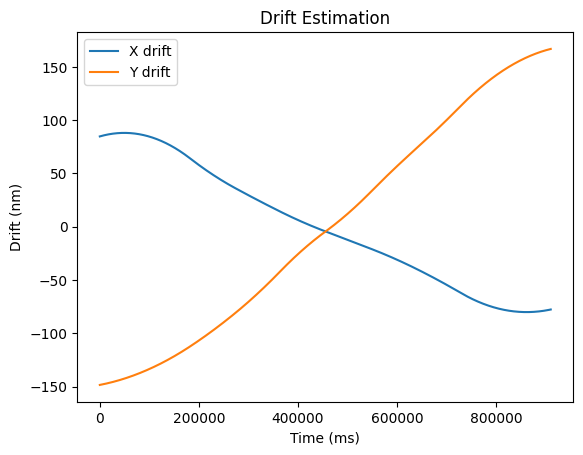

ERROR:root:Could not save drift correction data to/Users/trisso/Desktop/test/output/drift_correction.npz


Drift correction complete! 6482 localizations are found. 
 
Provided metadata: 
Driftcorrection RCC applied with settings {'frame_time_for_dme': 100, 'nr_time_bins': 10, 'zoom_level': 2, 'visualisation': True, 'ConvHist': True, 'storeLoc': '/Users/trisso/Desktop/test/output/drift_correction.npz'}.


In [13]:
#We next apply this drift correction to our fitting results
driftCorrData = DriftCorr_DME.DriftCorr_RCC(FittingResults[0],FindingResults[0],globalSettings, frame_time_for_dme=100, nr_time_bins=10, zoom_level=2, visualisation=True, ConvHist=True, storeLoc='/Users/trisso/Desktop/test/output/drift_correction.npz') #type:ignore
#Terminal information about this post-processing
print(f"Drift correction complete! {len(driftCorrData[0])} localizations are found. \n \nProvided metadata: \n{driftCorrData[1]}")

### Visualisation
Similar to above, visualisation can be easily performed like this:

In [14]:
#Obtain all available routines in Visualisation
AllAvailableFunction = utils.functionNamesFromDir("Visualisation")
AllAvailableFunctionUserData = utils.functionNamesFromDir(eve_data_folder+"/Visualisation")

#Give terminal information about the visualisation routines
print("All available Visualisation Routines:")
for index, function in enumerate(AllAvailableFunction):
    print(f"{index+1}: {function}")

if len(AllAvailableFunctionUserData) > 0:
    print(f"\nAdditional available Visualisation Routines from UserData folder ({eve_data_folder+'/Visualisation'}):")
    for index, function in enumerate(AllAvailableFunctionUserData):
        print(f"{index+1}: {function}")

#We can also request information about one of these functions:
print('\n')
print(utils.printInformationFromFunction('Histogram_Convolution.Histogram_convolution'))

All available Visualisation Routines:
1: Histogram_Convolution.Histogram_convolution
2: Gaussian_display.GaussianKernel_fixedSigma
3: Gaussian_display.GaussianKernel_locPrec


2D Histogram with circular kernel convolution
Help info 
Returns a test dictionary and metadata string, to check if the program is working properly.
Required parameters
Pixel size (nm) [PxSize]: 
	Pixel-to-pseudopixel ratio 
	Default value: 10
Convolution kernel size (nm) [Convolution_kernel]: 
	Convolution pixel size 
	Default value: 50



Visualisation complete! 
 
Provided metadata: 
0.005001308633915023


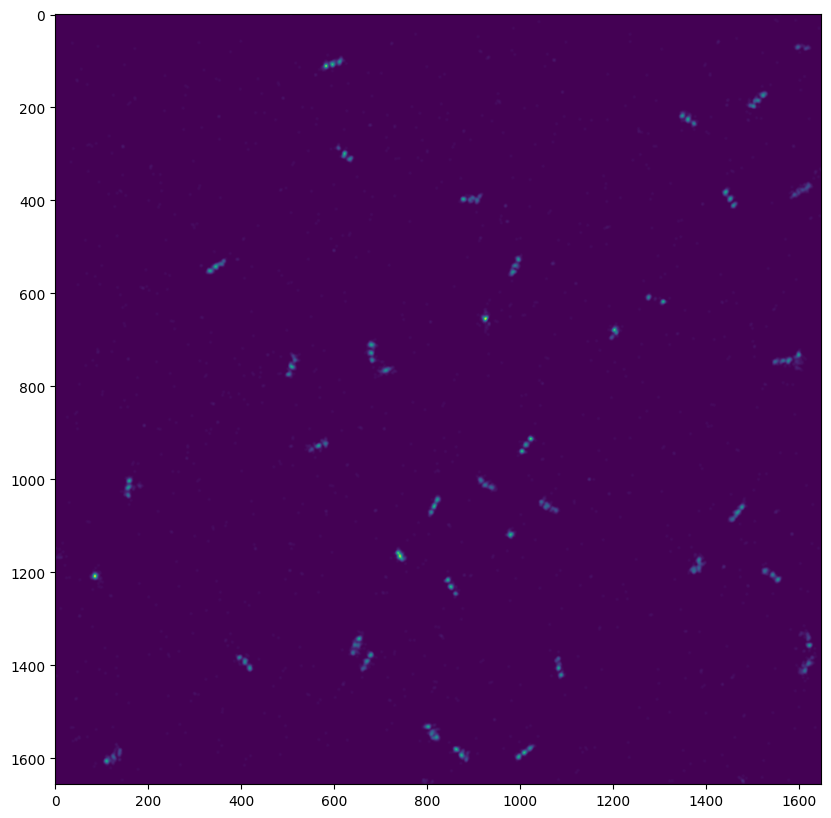

In [15]:
#We create the image based on this Gaussian-blurred visualisation
image = Histogram_Convolution.Histogram_convolution(driftCorrData[0],globalSettings, PxSize="5", Convolution_kernel=50) #type:ignore

print(f"Visualisation complete! \n \nProvided metadata: \n{image[1]}")

#And we visualise it
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
plt.imshow(image[0])